# Superstore Sales Analysis (2015 - 2018)

**Business question:** where do the company's sales come from, and where should it focus its attention?

**Questions this notebook answers**
1. How have sales changed over time, and when are the busiest months?
2. Which customer segments, regions, product categories and products drive sales?
3. How do customers ship their orders, and how long does each shipping mode take?

**Dataset:** Superstore sales records for the United States: 9,800 rows and 18 columns, with orders placed between January 2015 and December 2018. Each row is one product line within an order, so a single order can span several rows. The data contains **sales values only** (no profit, cost, discount or quantity), so this is an analysis of revenue, not profitability.

**Tools:** Python (pandas, matplotlib).

**Contents:** 1. Setup and loading, 2. Data audit and cleaning, 3. Single-column analysis (including distribution and outliers), 4. Sales over time, 5. Categories, products and states, 6. Delivery time by shipping mode, 7. Combining columns, 8. Key findings, 9. Recommendations, 10. Limitations

## 1. Setup and loading

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df = pd.read_excel(r"C:\Users\HomePC\Downloads\superstore_final_dataset kodex.xlsx")

## 2. Data audit and cleaning

First look at the data: its first rows, size, column types, summary statistics and missing values.

In [4]:
df.head()

,Row_ID,Order_ID,Order_Date,Ship_Date,Ship_Mode,Customer_ID,Customer_Name,Segment,Country,City,State,Postal_Code,Region,Product_ID,Category,Sub_Category,Product_Name,Sales
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O Donnel,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O Donnel,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold N Roll Cart System,22.3680


In [5]:
df['Segment'].value_counts()

Segment
Consumer       5101
Corporate      2953
Home Office    1746
Name: count, dtype: int64

In [6]:
df = df.drop_duplicates()

In [7]:
df.columns.unique()

Index(['Row_ID', 'Order_ID', 'Order_Date', 'Ship_Date', 'Ship_Mode',
       'Customer_ID', 'Customer_Name', 'Segment', 'Country', 'City', 'State',
       'Postal_Code', 'Region', 'Product_ID', 'Category', 'Sub_Category',
       'Product_Name', 'Sales'],
      dtype='object')

In [8]:
df.shape

(9800, 18)

In [9]:
df['Ship_Mode'].unique()

array(['Second Class', 'Standard Class', 'First Class', 'Same Day'],
      dtype=object)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row_ID         9800 non-null   int64         
 1   Order_ID       9800 non-null   object        
 2   Order_Date     9800 non-null   datetime64[ns]
 3   Ship_Date      9800 non-null   datetime64[ns]
 4   Ship_Mode      9800 non-null   object        
 5   Customer_ID    9800 non-null   object        
 6   Customer_Name  9800 non-null   object        
 7   Segment        9800 non-null   object        
 8   Country        9800 non-null   object        
 9   City           9800 non-null   object        
 10  State          9800 non-null   object        
 11  Postal_Code    9789 non-null   float64       
 12  Region         9800 non-null   object        
 13  Product_ID     9800 non-null   object        
 14  Category       9800 non-null   object        
 15  Sub_Category   9800 n

In [11]:
df.dropna()

,Row_ID,Order_ID,Order_Date,Ship_Date,Ship_Mode,Customer_ID,Customer_Name,Segment,Country,City,State,Postal_Code,Region,Product_ID,Category,Sub_Category,Product_Name,Sales
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O Donnel,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O Donnel,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold N Roll Cart System,22.3680
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9795,9796,CA-2017-125920,2017-05-21,2017-05-28,Standard Class,SH-19975,Sally Hughsby,Corporate,United States,Chicago,Illinois,60610.0,Central,OFF-BI-10003429,Office Supplies,Binders,"Cardinal HOLDit! Binder Insert Strips,Extra St...",3.7980
9796,9797,CA-2016-128608,2016-01-12,2016-01-17,Standard Class,CS-12490,Cindy Schnelling,Corporate,United States,Toledo,Ohio,43615.0,East,OFF-AR-10001374,Office Supplies,Art,"BIC Brite Liner Highlighters, Chisel Tip",10.3680
9797,9798,CA-2016-128608,2016-01-12,2016-01-17,Standard Class,CS-12490,Cindy Schnelling,Corporate,United States,Toledo,Ohio,43615.0,East,TEC-PH-10004977,Technology,Phones,GE 30524EE4,235.1880
9798,9799,CA-2016-128608,2016-01-12,2016-01-17,Standard Class,CS-12490,Cindy Schnelling,Corporate,United States,Toledo,Ohio,43615.0,East,TEC-PH-10000912,Technology,Phones,Anker 24W Portable Micro USB Car Charger,26.3760


In [12]:
df.describe()

,Row_ID,Order_Date,Ship_Date,Postal_Code,Sales
count,9800.000000,9800,9800,9789.000000,9800.000000
mean,4900.500000,2017-05-01 05:13:51.673469440,2017-05-05 04:17:52.653061120,55273.322403,230.769059
min,1.000000,2015-01-03 00:00:00,2015-01-07 00:00:00,1040.000000,0.444000
25%,2450.750000,2016-05-24 00:00:00,2016-05-27 18:00:00,23223.000000,17.248000
50%,4900.500000,2017-06-26 00:00:00,2017-06-29 00:00:00,58103.000000,54.490000
75%,7350.250000,2018-05-15 00:00:00,2018-05-19 00:00:00,90008.000000,210.605000
max,9800.000000,2018-12-30 00:00:00,2019-01-05 00:00:00,99301.000000,22638.480000
std,2829.160653,NaN,NaN,32041.223413,626.651875


In [13]:
df.isnull().sum()

Row_ID            0
Order_ID          0
Order_Date        0
Ship_Date         0
Ship_Mode         0
Customer_ID       0
Customer_Name     0
Segment           0
Country           0
City              0
State             0
Postal_Code      11
Region            0
Product_ID        0
Category          0
Sub_Category      0
Product_Name      0
Sales             0
dtype: int64

In [14]:
df.dtypes

Row_ID                    int64
Order_ID                 object
Order_Date       datetime64[ns]
Ship_Date        datetime64[ns]
Ship_Mode                object
Customer_ID              object
Customer_Name            object
Segment                  object
Country                  object
City                     object
State                    object
Postal_Code             float64
Region                   object
Product_ID               object
Category                 object
Sub_Category             object
Product_Name             object
Sales                   float64
dtype: object

**Pandas commands used in the audit**
- `df.head()` shows the first 5 rows
- `df.info()` shows column types and non-null counts
- `df.describe()` gives summary statistics
- `df.shape` gives the number of rows and columns
- `df.isnull().sum()` counts missing values per column
- `df.dtypes` shows the data type of each column

In [15]:
#check rows for white spaces
df.columns

Index(['Row_ID', 'Order_ID', 'Order_Date', 'Ship_Date', 'Ship_Mode',
       'Customer_ID', 'Customer_Name', 'Segment', 'Country', 'City', 'State',
       'Postal_Code', 'Region', 'Product_ID', 'Category', 'Sub_Category',
       'Product_Name', 'Sales'],
      dtype='object')

In [16]:
#we drop row id and postal code

df = df.drop(columns = ['Row_ID' , 'Postal_Code'] , axis = 1)

In [17]:
#missing values
df.isnull().sum()

Order_ID         0
Order_Date       0
Ship_Date        0
Ship_Mode        0
Customer_ID      0
Customer_Name    0
Segment          0
Country          0
City             0
State            0
Region           0
Product_ID       0
Category         0
Sub_Category     0
Product_Name     0
Sales            0
dtype: int64

### Fixing the date columns

`Order_Date` and `Ship_Date` are converted to dates using the day/month/year format, so that year, month and delivery-day calculations are reliable.

In [18]:
#changing date column
df['Order_Date'] = pd.to_datetime(df['Order_Date'],format = '%d/%m/%y')

In [19]:
df['Ship_Date'] = pd.to_datetime(df['Ship_Date'],format = '%d/%m/%y')

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Order_ID       9800 non-null   object        
 1   Order_Date     9800 non-null   datetime64[ns]
 2   Ship_Date      9800 non-null   datetime64[ns]
 3   Ship_Mode      9800 non-null   object        
 4   Customer_ID    9800 non-null   object        
 5   Customer_Name  9800 non-null   object        
 6   Segment        9800 non-null   object        
 7   Country        9800 non-null   object        
 8   City           9800 non-null   object        
 9   State          9800 non-null   object        
 10  Region         9800 non-null   object        
 11  Product_ID     9800 non-null   object        
 12  Category       9800 non-null   object        
 13  Sub_Category   9800 non-null   object        
 14  Product_Name   9800 non-null   object        
 15  Sales          9800 n

**What the audit shows**
- The data has 9,800 rows and 18 columns, and no duplicate rows were found.
- Only `Postal_Code` has missing values (11 rows). The column is not needed because `State` and `Region` already describe location, so it is dropped together with `Row_ID` instead of removing those 11 sales.
- `Order_Date` and `Ship_Date` already load as dates. The conversion step makes the day/month/year format explicit, so date calculations later (sales by year and month, delivery days) work reliably.
- Sales values are all positive (smallest value is $0.44), so there are no invalid amounts.

### Validating the columns

The columns are split by type, then the values of the main category columns and the `Sales` column are checked for anything unexpected.

In [21]:
# numerical columns
num_cols =df.select_dtypes(include =['int' , 'float'] )

In [22]:
#confirm
num_cols.head()


,Sales
0,261.9600
1,731.9400
2,14.6200
3,957.5775
4,22.3680


In [23]:
#extracting categorical 
cat_cols =df.select_dtypes(include =['object' , 'category'] )

In [24]:
cat_cols.head(1)

,Order_ID,Ship_Mode,Customer_ID,Customer_Name,Segment,Country,City,State,Region,Product_ID,Category,Sub_Category,Product_Name
0,CA-2017-152156,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase


In [25]:
#data validation
cat_cols['Category'].unique()

array(['Furniture', 'Office Supplies', 'Technology'], dtype=object)

In [26]:
cat_cols['Sub_Category'].value_counts()

Sub_Category
Binders        1492
Paper          1338
Furnishings     931
Phones          876
Storage         832
Art             785
Accessories     756
Chairs          607
Appliances      459
Labels          357
Tables          314
Envelopes       248
Bookcases       226
Fasteners       214
Supplies        184
Machines        115
Copiers          66
Name: count, dtype: int64

In [27]:
cat_cols['Product_Name'].unique()

array(['Bush Somerset Collection Bookcase',
       'Hon Deluxe Fabric Upholstered Stacking Chairs, Rounded Back',
       'Self-Adhesive Address Labels for Typewriters by Universal', ...,
       'Cisco 8961 IP Phone Charcoal', 'Eureka Hand Vacuum, Bagless',
       'LG G2'], shape=(1849,), dtype=object)

In [28]:
#data validation for numerical columns (we do this to check if we have negative value)
num_cols['Sales'].value_counts()

Sales
12.960     55
15.552     39
19.440     39
10.368     35
25.920     34
           ..
339.136     1
60.048      1
5.022       1
7.857       1
10.384      1
Name: count, Length: 5757, dtype: int64

### Splitting columns by type

The numeric and text columns are separated so each group can be checked and summarised in the way that suits it. Identifier columns (`Order_ID`, `Customer_ID`, `Product_ID`) are removed from the text columns because they are only labels and do not describe anything worth charting. The two parts are then joined back into `df1`, which is used for the single-column charts below. `df1` has no date columns, so the time-based analysis later uses `df`.

In [29]:
#we drop customer id and order id because they are not needed in the analysis
cat_cols = cat_cols.drop(columns = ['Order_ID' , 'Customer_ID' ,'Product_ID' ] , axis = 1)

In [30]:
#to combine our numerical and categorical column 
df1 = pd.concat([num_cols,cat_cols], axis = 1)

In [31]:
#check
df1.head(1)

,Sales,Ship_Mode,Customer_Name,Segment,Country,City,State,Region,Category,Sub_Category,Product_Name
0,261.96,Second Class,Claire Gute,Consumer,United States,Henderson,Kentucky,South,Furniture,Bookcases,Bush Somerset Collection Bookcase


## 3. Single-column analysis

This section looks at one column at a time. Note that the counts below are **order lines** (rows), not unique orders: the data has 9,800 order lines but only 4,922 unique orders.

In [32]:
#working with categorical columns
cat_cols.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Ship_Mode      9800 non-null   object
 1   Customer_Name  9800 non-null   object
 2   Segment        9800 non-null   object
 3   Country        9800 non-null   object
 4   City           9800 non-null   object
 5   State          9800 non-null   object
 6   Region         9800 non-null   object
 7   Category       9800 non-null   object
 8   Sub_Category   9800 non-null   object
 9   Product_Name   9800 non-null   object
dtypes: object(10)
memory usage: 765.8+ KB


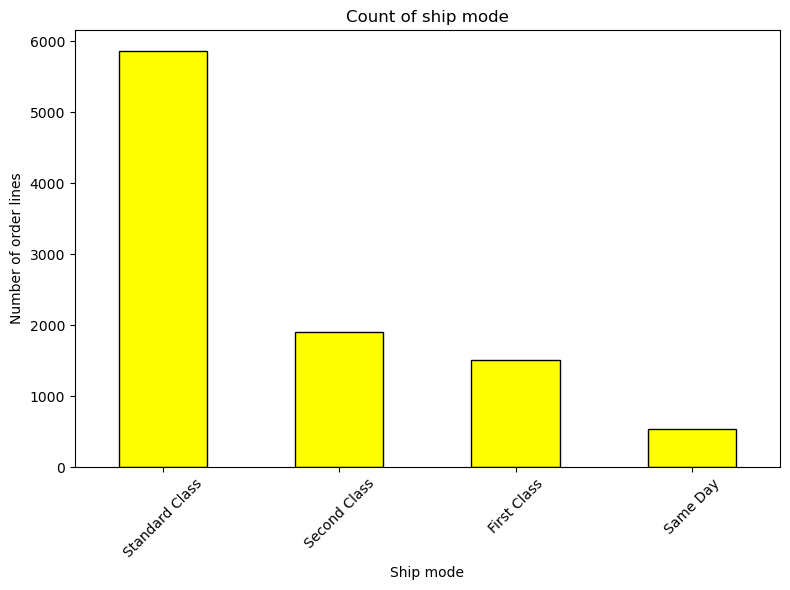

In [33]:
# create a bar chart f0r ship mode
count_ship_mode = cat_cols['Ship_Mode'].value_counts()

#for the shape and size
plt.figure(figsize = (8,6))

#for customisation
count_ship_mode.plot(kind = 'bar', color = 'yellow' ,edgecolor = 'black')
    
plt.title('Count of ship mode')
plt.ylabel('Number of order lines')
plt.xlabel('Ship mode')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [34]:
df1['Segment'].unique()

array(['Consumer', 'Corporate', 'Home Office'], dtype=object)

**Shipping mode.** The company offers four shipping modes: Standard Class, Second Class, First Class and Same Day. Standard Class is by far the most used (5,859 order lines, about 60% of the total), followed by Second Class and First Class, with Same Day the least used.

**Business recommendations**
1. Review the pricing and value of the faster shipping modes. A likely reason for Standard Class dominating is cost, but the dataset has no shipping price, so this cannot be confirmed here.
2. Promotions could encourage customers to try shipping modes other than Standard Class.
3. Compare delivery times across shipping modes to check that customers get value for money when they pay for faster shipping. This is done in section 6.

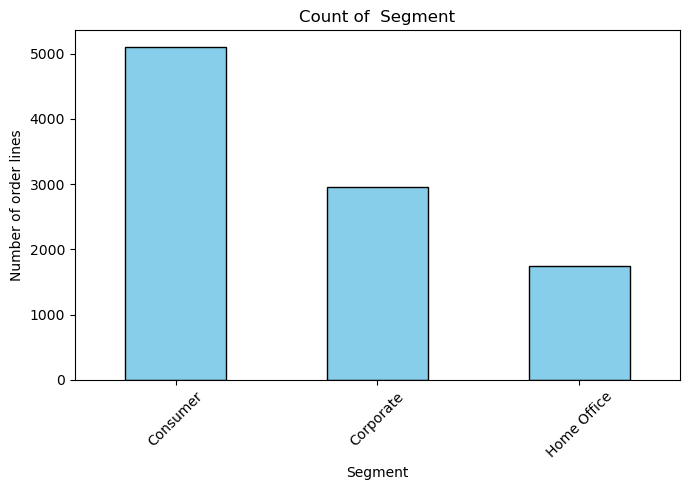

In [35]:
# create a bar chart f0r ship mode
count_of_Segment = cat_cols['Segment'].value_counts()

#for the shape and size
plt.figure(figsize = (7,5))

#for customisation
count_of_Segment.plot(kind = 'bar', color = 'skyblue' ,edgecolor = 'black')
    
plt.title('Count of  Segment')
plt.ylabel('Number of order lines')
plt.xlabel('Segment')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [36]:
df['Segment'].unique()
df['Category'].unique()

array(['Furniture', 'Office Supplies', 'Technology'], dtype=object)

**Customer segment.** Consumers account for the most order lines (5,101, about 52%), followed by Corporate (2,953) and Home Office (1,746). The business therefore serves mainly individual consumers rather than business customers.

**Business recommendations**
1. Since most orders come from consumers, keep the buying experience simple and seamless.
2. Keep product availability, pricing and customer support strong for this segment.
3. Home Office is the smallest segment, which suggests room for growth through targeted outreach or tailored offers.
4. Consider segment-based marketing.

In [37]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Sales          9800 non-null   float64
 1   Ship_Mode      9800 non-null   object 
 2   Customer_Name  9800 non-null   object 
 3   Segment        9800 non-null   object 
 4   Country        9800 non-null   object 
 5   City           9800 non-null   object 
 6   State          9800 non-null   object 
 7   Region         9800 non-null   object 
 8   Category       9800 non-null   object 
 9   Sub_Category   9800 non-null   object 
 10  Product_Name   9800 non-null   object 
dtypes: float64(1), object(10)
memory usage: 842.3+ KB


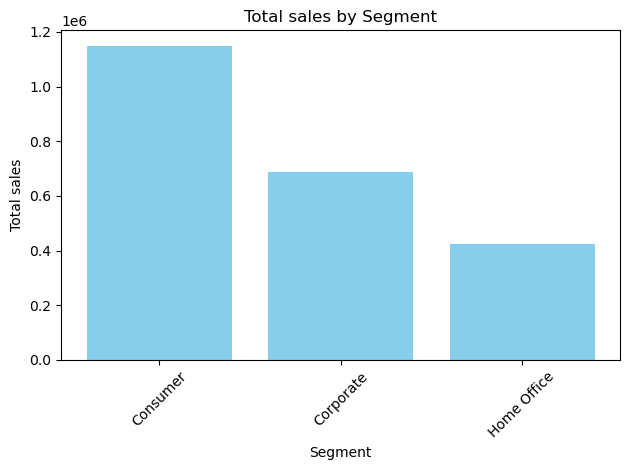

In [38]:
# sale segment by sales
sales_segment = df1.groupby('Segment')['Sales'].sum().reset_index()

# figure of bar chart

#sales_segment.plot(kind = 'bar', color = 'skyblue')

plt.bar(sales_segment['Segment'],sales_segment ['Sales'],color = 'skyblue')
plt.title('Total sales by Segment')
plt.ylabel('Total sales')
plt.xlabel('Segment')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Total sales by segment.** Consumers generate about $1.15 million (51% of sales), Corporate about $688,000 (30%) and Home Office about $425,000 (19%). Sales follow the same order as the order-line counts.

In [39]:
# sales by region
df1['Region'].unique()

array(['South', 'West', 'Central', 'East'], dtype=object)

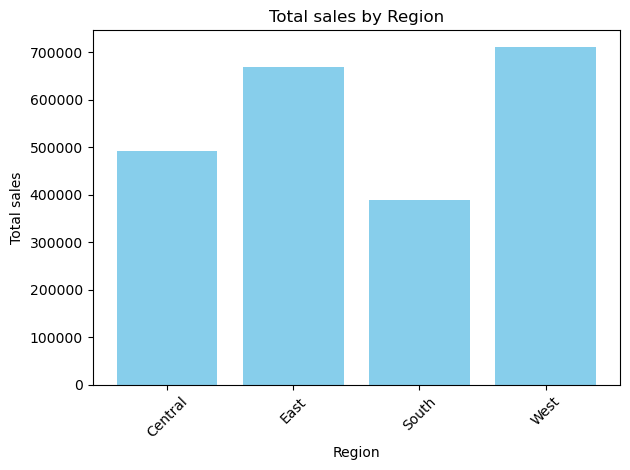

In [40]:
sales_region = df1.groupby('Region')['Sales'].sum().reset_index()

# figure of bar chart

#sales_segment.plot(kind = 'bar', color = 'skyblue')

plt.bar(sales_region['Region'],sales_region['Sales'],color = 'skyblue')
plt.title('Total sales by Region')
plt.ylabel('Total sales')
plt.xlabel('Region')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Total sales by region.** The West has the highest sales (about $710,000, 31% of the total), followed by the East ($670,000), Central ($493,000) and South ($389,000). The West and East together bring in about 61% of all sales.

### Distribution of sales values and outliers

The charts so far compare groups. This part looks at the individual sales values: how they are spread and whether any are unusually large. A histogram shows the spread, and a box plot shows the median, the typical range and the outliers (the points beyond the whiskers).

count     9800.00
mean       230.77
std        626.65
min          0.44
25%         17.25
50%         54.49
75%        210.60
max      22638.48
Name: Sales, dtype: float64


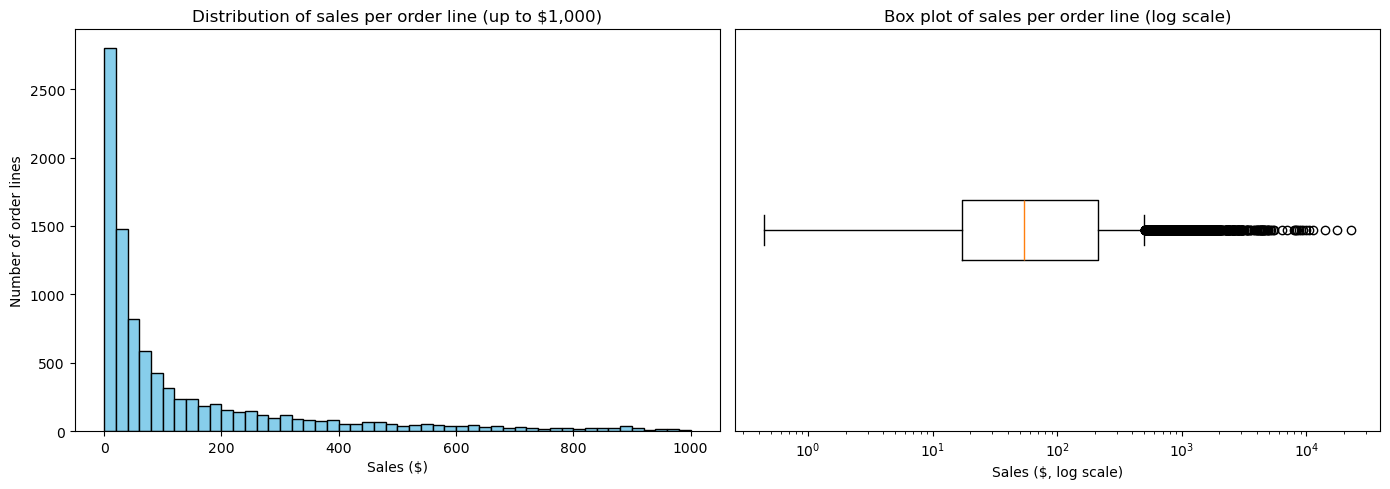

In [41]:
# Spread of individual sales values
print(df['Sales'].describe().round(2))

plt.figure(figsize = (14,5))

# Left: histogram of sales up to $1,000 (a few very large values are left out so the main shape is visible)
plt.subplot(1, 2, 1)
plt.hist(df['Sales'], bins = 50, range = (0, 1000), color = 'skyblue', edgecolor = 'black')
plt.title('Distribution of sales per order line (up to $1,000)')
plt.xlabel('Sales ($)')
plt.ylabel('Number of order lines')

# Right: box plot on a log scale, so both small and very large values can be seen
plt.subplot(1, 2, 2)
plt.boxplot(df['Sales'], vert = False)
plt.xscale('log')
plt.title('Box plot of sales per order line (log scale)')
plt.xlabel('Sales ($, log scale)')
plt.yticks([])

plt.tight_layout()
plt.show()

In [42]:
# Outlier check with the IQR rule: a value is an outlier if it is more than 1.5 x IQR above Q3
q1 = df['Sales'].quantile(0.25)
q3 = df['Sales'].quantile(0.75)
iqr = q3 - q1
upper_limit = q3 + 1.5 * iqr

outliers = df[df['Sales'] > upper_limit]

print(f"Upper limit (Q3 + 1.5 x IQR):      ${upper_limit:,.2f}")
print(f"Order lines above the limit:       {len(outliers):,} ({len(outliers) / len(df) * 100:.1f}% of lines)")
print(f"Share of total sales they make up: {outliers['Sales'].sum() / df['Sales'].sum() * 100:.1f}%")
print()
print("Largest order lines:")
df.nlargest(5, 'Sales')[['Product_Name', 'Category', 'Sales']]

Upper limit (Q3 + 1.5 x IQR):      $500.64
Order lines above the limit:       1,145 (11.7% of lines)
Share of total sales they make up: 64.3%

Largest order lines:


,Product_Name,Category,Sales
2697,Cisco TelePresence System EX90 Videoconferenci...,Technology,22638.480
6826,Canon imageCLASS 2200 Advanced Copier,Technology,17499.950
8153,Canon imageCLASS 2200 Advanced Copier,Technology,13999.960
2623,Canon imageCLASS 2200 Advanced Copier,Technology,11199.968
4190,Canon imageCLASS 2200 Advanced Copier,Technology,10499.970


**Sales values are very uneven.** The typical order line is small: the median is $54.49, far below the average of $230.77, and about 62% of lines are $100 or less. A small number of very large lines pull the average up, and the largest is $22,638 (a Cisco videoconferencing unit).

**Outliers.** By the IQR rule, any line above about $501 counts as an outlier. That is 1,145 lines (11.7%), and together they make up about 64% of all sales. There are no outliers on the low side.

**The outliers are kept.** They are real purchases of high-value products (459 Furniture, 394 Technology and 292 Office Supplies lines), not data errors, and removing them would remove most of the revenue. Because of this skew, the median describes a typical order line better than the average, and totals for any group can be strongly influenced by a few large orders.

### Headline numbers

In [43]:
# Headline numbers
total_sales = df['Sales'].sum()
n_orders = df['Order_ID'].nunique()            # unique orders (one order can have several rows)
n_customers = df['Customer_ID'].nunique()
avg_order_value = df.groupby('Order_ID')['Sales'].sum().mean()

print(f"Total sales:         ${total_sales:,.0f}")
print(f"Number of orders:    {n_orders:,}")
print(f"Number of customers: {n_customers:,}")
print(f"Average order value: ${avg_order_value:,.2f}")
print(f"Period covered:      {df['Order_Date'].min().date()} to {df['Order_Date'].max().date()}")

Total sales:         $2,261,537
Number of orders:    4,922
Number of customers: 793
Average order value: $459.48
Period covered:      2015-01-03 to 2018-12-30


## 4. Sales over time

The order date is used to see how sales change across years and across months of the year. A `Year` and a `Month` column are created from `Order_Date`.

In [44]:
# Total sales for each year, with the % change from the previous year
df['Year'] = df['Order_Date'].dt.year
sales_year = df.groupby('Year')['Sales'].sum().reset_index()
sales_year['Growth_%'] = (sales_year['Sales'].pct_change() * 100).round(1)
sales_year

,Year,Sales,Growth_%
0,2015,479856.2081,NaN
1,2016,459436.0054,-4.3
2,2017,600192.5500,30.6
3,2018,722052.0192,20.3


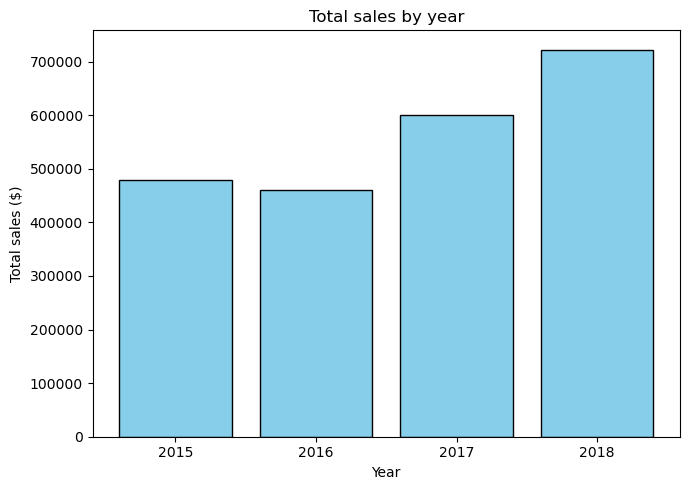

In [45]:
plt.figure(figsize = (7,5))
plt.bar(sales_year['Year'].astype(str), sales_year['Sales'], color = 'skyblue', edgecolor = 'black')
plt.title('Total sales by year')
plt.ylabel('Total sales ($)')
plt.xlabel('Year')
plt.tight_layout()
plt.show()

**Sales by year.** Sales dipped slightly in 2016 (down 4.3%), then grew strongly: up 30.6% in 2017 and 20.3% in 2018, reaching about $722,000. Growth has been strong for two years in a row.

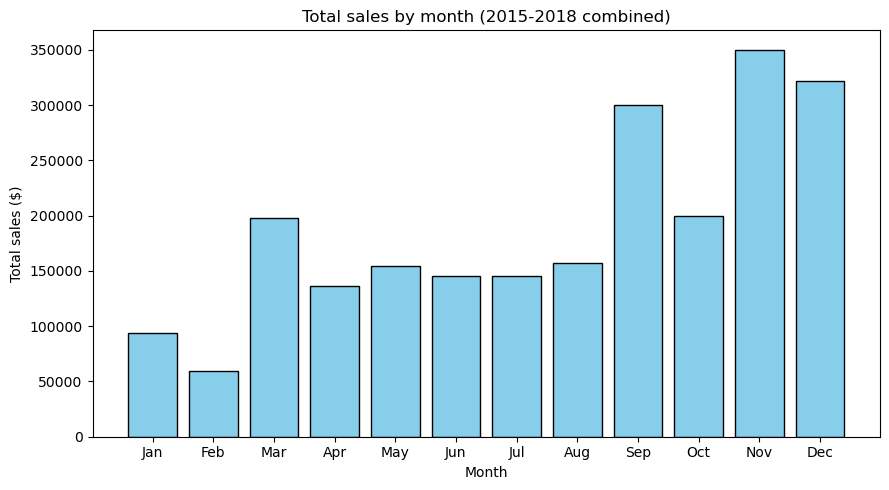

In [46]:
# Total sales for each month of the year (all four years combined)
df['Month'] = df['Order_Date'].dt.month
sales_month = df.groupby('Month')['Sales'].sum()

month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

plt.figure(figsize = (9,5))
plt.bar(month_names, sales_month.values, color = 'skyblue', edgecolor = 'black')
plt.title('Total sales by month (2015-2018 combined)')
plt.ylabel('Total sales ($)')
plt.xlabel('Month')
plt.tight_layout()
plt.show()

**Sales by month (all four years combined).** Sales are strongly seasonal. September, November and December together account for about 43% of all sales, with November the highest month. January and February are the weakest, bringing in only about 7% of sales between them.

## 5. Categories, products and states

In [47]:
# Sales, number of order lines and average line value for each category
category_summary = df.groupby('Category')['Sales'].agg(Order_Lines = 'count', Total_Sales = 'sum', Avg_Line_Sales = 'mean').round(0)
category_summary['Share_%'] = (category_summary['Total_Sales'] / category_summary['Total_Sales'].sum() * 100).round(1)
category_summary.sort_values('Total_Sales', ascending = False)

,Order_Lines,Total_Sales,Avg_Line_Sales,Share_%
Category,,,,
Technology,1813,827456.0,456.0,36.6
Furniture,2078,728659.0,351.0,32.2
Office Supplies,5909,705422.0,119.0,31.2


**Sales by category.** Technology brings in the most sales (about $827,000, 37%), followed by Furniture (32%) and Office Supplies (31%). Office Supplies has by far the most order lines (5,909) but the lowest average value per line (about $119), so it is a high-volume, low-value category, while Technology averages about $456 per line.

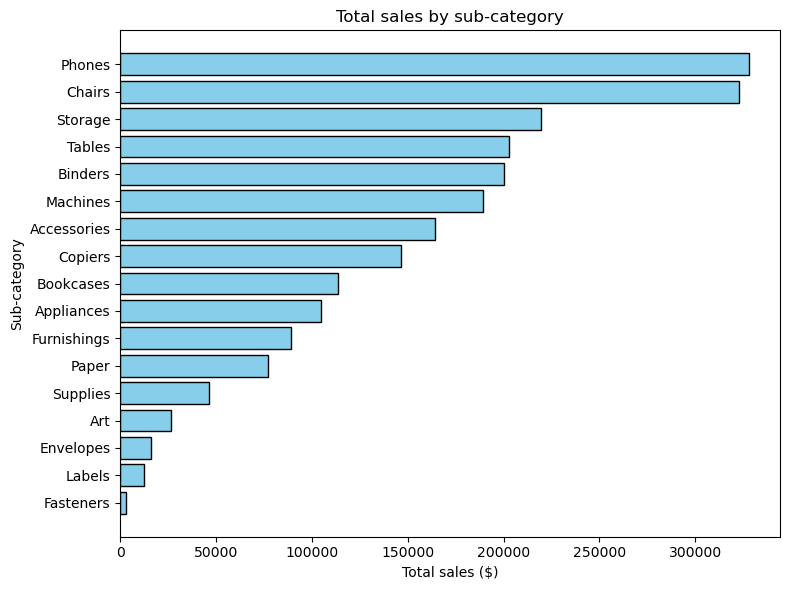

In [48]:
# Total sales for each sub-category, smallest at the bottom of the chart
sales_sub = df.groupby('Sub_Category')['Sales'].sum().sort_values()

plt.figure(figsize = (8,6))
plt.barh(sales_sub.index, sales_sub.values, color = 'skyblue', edgecolor = 'black')
plt.title('Total sales by sub-category')
plt.xlabel('Total sales ($)')
plt.ylabel('Sub-category')
plt.tight_layout()
plt.show()

**Sales by sub-category.** Phones (about $328,000) and Chairs (about $323,000) are the two biggest sub-categories. At the other end, Fasteners (about $3,000), Labels, Envelopes and Art each bring in less than $27,000, and the four smallest sub-categories together make up only about 2.6% of sales.

In [49]:
# Top 5 states by total sales
top_states = df.groupby('State')['Sales'].sum().sort_values(ascending = False).head(5).reset_index()
top_states['Share_%'] = (top_states['Sales'] / df['Sales'].sum() * 100).round(1)
top_states

,State,Sales,Share_%
0,California,446306.4635,19.7
1,New York,306361.1470,13.5
2,Texas,168572.5322,7.5
3,Washington,135206.8500,6.0
4,Pennsylvania,116276.6500,5.1


**Top states.** California alone accounts for about 20% of all sales, and New York for about 13.5%. Together with Texas, Washington and Pennsylvania, the top five states account for about 52% of sales, so sales are concentrated in a small number of states.

## 6. Delivery time by shipping mode

Delivery time is the number of days between `Order_Date` and `Ship_Date`. This checks whether faster shipping modes really are faster, and whether they are used for bigger purchases.

In [50]:
# Days between order and shipping, and average line value, for each shipping mode
df['Delivery_Days'] = (df['Ship_Date'] - df['Order_Date']).dt.days

shipping_summary = df.groupby('Ship_Mode').agg(
    Order_Lines = ('Sales', 'count'),
    Avg_Delivery_Days = ('Delivery_Days', 'mean'),
    Avg_Line_Sales = ('Sales', 'mean')).round(2).sort_values('Avg_Delivery_Days')
shipping_summary

,Order_Lines,Avg_Delivery_Days,Avg_Line_Sales
Ship_Mode,,,
Same Day,538,0.04,232.75
First Class,1501,2.18,230.23
Second Class,1902,3.25,236.55
Standard Class,5859,5.01,228.85


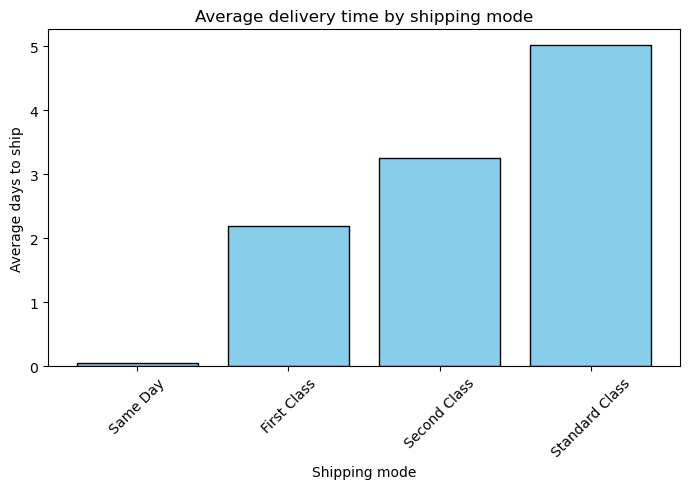

In [51]:
plt.figure(figsize = (7,5))
plt.bar(shipping_summary.index, shipping_summary['Avg_Delivery_Days'], color = 'skyblue', edgecolor = 'black')
plt.title('Average delivery time by shipping mode')
plt.ylabel('Average days to ship')
plt.xlabel('Shipping mode')
plt.xticks(rotation = 45)
plt.tight_layout()
plt.show()

**Delivery time.** The shipping modes behave as expected: Same Day ships on the day of the order (about 0.04 days on average), First Class takes about 2.2 days, Second Class about 3.3 days and Standard Class about 5.0 days. The average value of an order line is almost the same for every mode (between about $229 and $237), so customers do not choose faster shipping for larger purchases.

## 7. Combining columns

Two columns are looked at together to see whether patterns change between groups.

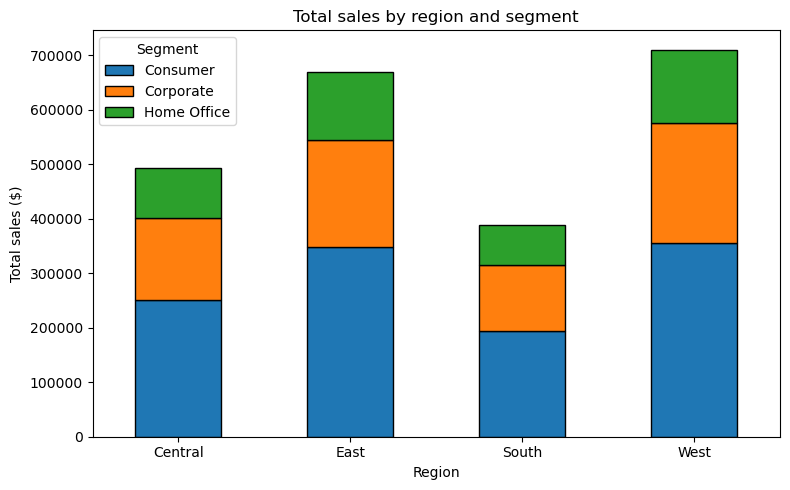

In [52]:
# Sales by region, split by customer segment
region_segment = df.pivot_table(index = 'Region', columns = 'Segment', values = 'Sales', aggfunc = 'sum')

region_segment.plot(kind = 'bar', stacked = True, figsize = (8,5), edgecolor = 'black')
plt.title('Total sales by region and segment')
plt.ylabel('Total sales ($)')
plt.xlabel('Region')
plt.xticks(rotation = 0)
plt.tight_layout()
plt.show()

**Region and segment.** The mix of customer segments is almost the same in every region: Consumers are about 50-52% of sales everywhere, Corporate about 29-31% and Home Office about 18-19%. The regions differ in size, not in customer mix.

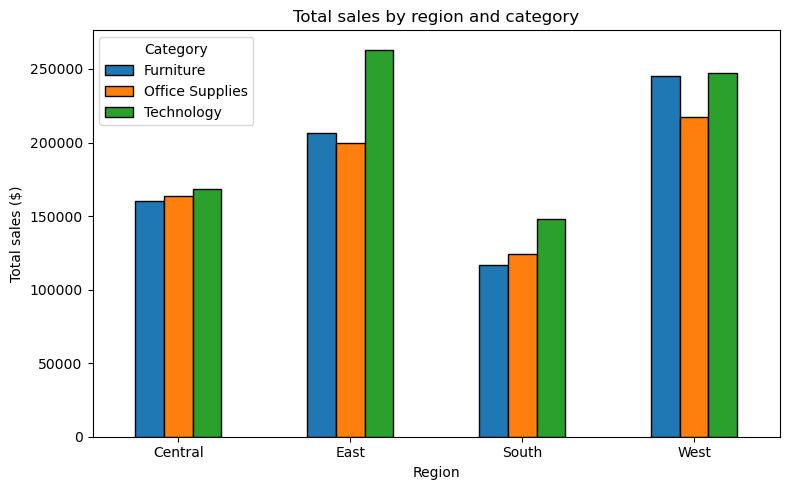

In [53]:
# Sales by region, split by product category
region_category = df.pivot_table(index = 'Region', columns = 'Category', values = 'Sales', aggfunc = 'sum')

region_category.plot(kind = 'bar', figsize = (8,5), edgecolor = 'black')
plt.title('Total sales by region and category')
plt.ylabel('Total sales ($)')
plt.xlabel('Region')
plt.xticks(rotation = 0)
plt.tight_layout()
plt.show()

**Region and category.** Technology is the largest category in the East, South and Central regions. In the West, Technology and Furniture are almost level (about $245,000 each), with Office Supplies a little behind.

In [54]:
# Share (%) of order lines using each shipping mode, within each region
ship_by_region = pd.crosstab(df['Region'], df['Ship_Mode'], normalize = 'index') * 100
ship_by_region.round(1)

Ship_Mode,First Class,Same Day,Second Class,Standard Class
Region,,,,
Central,12.8,5.2,19.6,62.4
East,16.9,5.5,18.7,58.9
South,14.5,5.2,20.3,59.9
West,16.1,5.8,19.4,58.6


**Shipping mode by region.** Standard Class makes up between about 59% and 62% of order lines in every region, so shipping habits do not differ much by region.

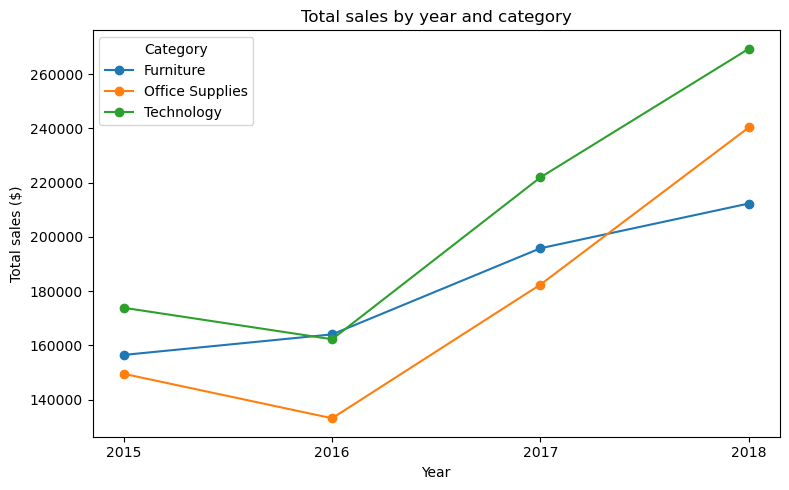

Category,Furniture,Office Supplies,Technology
Year,,,
2015,NaN,NaN,NaN
2016,4.8,-11.0,-6.7
2017,19.4,37.0,36.8
2018,8.4,31.8,21.4


In [55]:
# Sales by year for each category, and the % change from the previous year
year_category = df.pivot_table(index = 'Year', columns = 'Category', values = 'Sales', aggfunc = 'sum')

year_category.plot(kind = 'line', marker = 'o', figsize = (8,5))
plt.title('Total sales by year and category')
plt.ylabel('Total sales ($)')
plt.xlabel('Year')
plt.xticks(year_category.index)
plt.tight_layout()
plt.show()

(year_category.pct_change() * 100).round(1)

**Category growth by year.** All three categories grew in 2017 and 2018. Office Supplies grew fastest in 2018 (up 31.8%), then Technology (up 21.4%) and Furniture (up 8.4%). Furniture is growing the slowest.

## 8. Key findings

| Metric | Value |
|---|---|
| Total sales (2015-2018) | about $2.26 million |
| Unique orders | 4,922 |
| Unique customers | 793 |
| Average order value | about $460 |

- **Sales are growing.** After a small dip in 2016 (down 4.3%), sales grew 30.6% in 2017 and 20.3% in 2018.
- **Sales are seasonal.** September, November and December bring in about 43% of sales, while January and February bring in about 7%.
- **Consumers are the core customers.** They generate about 51% of sales, and the customer mix is the same in every region.
- **The West and East lead.** They make up about 61% of sales. California alone accounts for about 20%.
- **Technology is the biggest category** (37% of sales), while Office Supplies sells in the highest volume but at the lowest value per line.
- **A few sub-categories carry the business.** Phones and Chairs lead, while Fasteners, Labels, Envelopes and Art each bring in under $27,000.
- **Sales values are very uneven.** The median order line is about $54 but the average is about $231. Lines above about $501 are 11.7% of the total and make up about 64% of sales.
- **Standard Class is used for about 60% of order lines.** Faster modes do deliver faster (Same Day about 0.04 days, Standard about 5.0 days), but they are not used for bigger purchases.

## 9. Recommendations

1. **Prepare for the September to December peak.** Make sure stock and delivery capacity are ready for the months that bring in about 43% of sales.
2. **Build demand in January and February.** These months are the weakest, so promotions or bundles could help fill the gap.
3. **Protect the biggest markets.** California, New York and the West and East regions drive most of the sales, so keep service strong there while looking for growth in the Central and South regions.
4. **Focus on high-value sub-categories and review the weakest.** Phones, Chairs, Storage, Tables and Binders lead on sales, while the smallest sub-categories could be reviewed (range, pricing or promotion) to see if they are worth keeping.
5. **Grow Home Office and Corporate customers** through targeted offers, since Consumers make up half of all sales.
6. **Test promotions on faster shipping.** Standard Class dominates and faster modes are not linked to bigger orders, so offers on First Class or Second Class could be tested.

## 10. Limitations

- **Revenue only:** the data has no profit, cost, discount or quantity columns, so the analysis cannot show which products or regions are actually profitable.
- **Order lines, not orders:** the counts of rows are order lines. A single order can have several lines.
- **Limited period and place:** the data covers 2015 to 2018 and one country, so the results may not describe the current business.
- **Dropped columns:** `Postal_Code` (11 missing values) and the identifier columns were removed.
- **Shipping cost is unknown:** the data has no shipping price, so the reasons customers choose each shipping mode cannot be tested.
- **A few large orders dominate:** about 12% of order lines (those above about $501) make up 64% of sales, so totals can be swayed by a handful of big purchases. They were kept because they are real sales.
- **Descriptive only:** the patterns shown are associations in this dataset, not proven causes.

## 11. Next step

- Adding profit and discount data (if available) to see which products and regions are truly profitable but unfortunately it wasn't part of my dataset and i was officially told it was delibrately ommited.
- I Built an interactive dashboard of these results in Power BI.
- 

In [58]:
df.to_csv("superstore_data_N02", index=False)